# Análise Exploratória de Dados (AED)

Este notebook foi criado para organizar a análise exploratória dos dados do projeto. Os objetivos são:  (1) Entender estrutura e qualidade dos dados; (2) Identificar padrões iniciais e possíveis outliers; e (3) Preparar insights para etapas posteriores do projeto.

### Introdução

A Aventura é uma produtora e gestora cultural referência no Brasil, com forte atuação na criação de espetáculos e na gestão de teatros, promovendo experiências artísticas de alta qualidade para diferentes públicos. Inserido nesse contexto, o projeto propõe o desenvolvimento de uma solução digital para o Portal Aventura, com foco em ampliar o alcance de seus conteúdos e fortalecer a conexão entre espectadores e o ecossistema cultural da empresa.

### Contextualização do Problema

Atualmente, o Portal Aventura não possui um sistema estruturado de recomendação de conteúdos e espetáculos. Dessa forma, a navegação do usuário ocorre principalmente a partir do acesso a páginas específicas, sem a apresecntação de sugestões relacionadas a outras experiências disponíveis no portal, o que pode reduzir o potencial de conversão e geração de receita.

### Objetivo do Sistema

O objetivo do sistema é desenvolver uma solução de recomendação inteligente capaz de sugerir espetáculos, conteúdos e experiências alinhadas aos interesses dos usuários. Com isso, busca-se aumentar o tempo de permanência no portal, estimular a navegação entre diferentes conteúdos e impulsionar a venda de ingressos, criando uma jornada mais conectada e personalizada dentro do ecossistema da Aventura.

# Importação dos dados e tratamento

In [127]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style="whitegrid")

base_path = Path("../database_sympla.csv")

if not base_path.exists():
    raise FileNotFoundError(f"Arquivo não encontrado em: {base_path}")

df = pd.read_csv(base_path)

# Cópia para transformações de análise
df_eda = df.copy()

# Tratando vírgula/ponto e possíveis símbolos
df_eda["VALOR_NUM"] = (
    df_eda["VALOR DO INGRESSO"].astype(str)
    .str.replace(r"[^0-9,.-]", "", regex=True)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)
df_eda["VALOR_NUM"] = pd.to_numeric(df_eda["VALOR_NUM"], errors="coerce")

# Conversão de datas
df_eda["DATA_APRESENTACAO_DT"] = pd.to_datetime(df_eda["DATA DA APRESENTAÇÃO"], errors="coerce")
df_eda["DATA_COMPRA_DT"] = pd.to_datetime(df_eda["DATA DA COMPRA"], errors="coerce")

# Antecedência de compra em dias (compra -> apresentação), arredondada para inteiro
df_eda["ANTECEDENCIA_DIAS"] = (
    (df_eda["DATA_APRESENTACAO_DT"] - df_eda["DATA_COMPRA_DT"]).dt.total_seconds() / 86400
).round().astype("Int64")

print(f"Linhas: {df_eda.shape[0]} | Colunas: {df_eda.shape[1]}")
df_eda.head()

C:\Users\Inteli\AppData\Local\Temp\ipykernel_10140\3155347632.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_eda["DATA_APRESENTACAO_DT"] = pd.to_datetime(df_eda["DATA DA APRESENTAÇÃO"], errors="coerce")
C:\Users\Inteli\AppData\Local\Temp\ipykernel_10140\3155347632.py:30: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_eda["DATA_COMPRA_DT"] = pd.to_datetime(df_eda["DATA DA COMPRA"], errors="coerce")


Linhas: 343758 | Colunas: 14


,ID COMPRADOR.1.ID USUÁRIO,NOME ESPETÁCULO,TEATRO,DATA DA APRESENTAÇÃO,DATA DA COMPRA,SETOR,VALOR DO INGRESSO,MÉTODO DE PAGAMENTO,CANAL DA VENDA,TIPO,VALOR_NUM,DATA_APRESENTACAO_DT,DATA_COMPRA_DT,ANTECEDENCIA_DIAS
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,BOLETO,WEB,Show Stand-Up,120.0,2021-06-26 20:00:00,2021-05-20 05:03:00,38
1,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,BOLETO,WEB,Show Stand-Up,120.0,2021-06-26 20:00:00,2021-05-20 05:03:00,38
2,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,CARTAO DE CREDITO,WEB,Show Musical,50.0,2023-06-09 20:00:00,2023-06-09 10:04:00,0
3,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,CARTAO DE CREDITO,WEB,Show Musical,50.0,2023-06-09 20:00:00,2023-06-09 10:04:00,0
4,3,A NOVIÇA REBELDE,TEATRO RIACHUELO RJ,5/11/24 19:00,5/10/24 20:33,PLATEIA,225,CARTAO DE CREDITO,WEB,Espetáculo Musical,225.0,2024-05-11 19:00:00,2024-05-10 20:33:00,1


## Criação do dataset para sistema de recomendação

In [128]:
# CRIAÇÃO DO DATASET PARA CF (FILTRAGEM COLABORATIVA)

# Selecionar colunas necessárias
df_rec = df_eda[
    [
        "ID COMPRADOR.1.ID USUÁRIO",
        "NOME ESPETÁCULO",
        "VALOR_NUM",
        "TIPO"
    ]
].copy()

# Remover nulos essenciais
df_rec = df_rec.dropna(subset=["ID COMPRADOR.1.ID USUÁRIO", "NOME ESPETÁCULO"])

# Padronizar texto
df_rec["NOME ESPETÁCULO"] = df_rec["NOME ESPETÁCULO"].astype(str).str.strip()
df_rec["TIPO"] = df_rec["TIPO"].astype(str).str.strip()


# AGRUPAMENTO
dataset = (
    df_rec
    .groupby(["ID COMPRADOR.1.ID USUÁRIO", "NOME ESPETÁCULO"])
    .agg(
        ranking=("NOME ESPETÁCULO", "size"),
        valor_medio_ingresso=("VALOR_NUM", "mean"),
        tipo_evento=("TIPO", "first")
    )
    .reset_index()
)


# PADRONIZAÇÃO FINAL
dataset = dataset.rename(columns={
    "ID COMPRADOR.1.ID USUÁRIO": "user_id",
    "NOME ESPETÁCULO": "item_id"
})

dataset = dataset[
    ["user_id", "item_id", "ranking", "valor_medio_ingresso", "tipo_evento"]
]


# Salvar CSV
output_path = Path("../dataset/dataset.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

dataset.to_csv(output_path, index=False)

print("Dataset salvo em:", output_path)
dataset.head()

Dataset salvo em: ..\dataset\dataset.csv


,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,2,120.0,Show Stand-Up
1,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,2,50.0,Show Musical
2,3,A NOVIÇA REBELDE,1,225.0,Espetáculo Musical
3,4,MUSICAL HAIRSPRAY,1,350.0,Espetáculo Musical
4,5,A NOVIÇA REBELDE,2,125.0,Espetáculo Musical


## Carregamento do dataset final

In [129]:
df_dataset = pd.read_csv("../dataset/dataset.csv")
df_dataset.head()

,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,2,120.0,Show Stand-Up
1,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,2,50.0,Show Musical
2,3,A NOVIÇA REBELDE,1,225.0,Espetáculo Musical
3,4,MUSICAL HAIRSPRAY,1,350.0,Espetáculo Musical
4,5,A NOVIÇA REBELDE,2,125.0,Espetáculo Musical


## 1) Descrição do dataset final de recomendação

Nesta etapa respondemos:
- Quantas linhas e colunas existem?
- O que cada variável representa?
- Existem dados faltantes?
- Há registros duplicados?

In [130]:
print(f"Dimensão do dataset final: {df_dataset.shape[0]:,} linhas x {df_dataset.shape[1]} colunas".replace(",", "."))

dicionario = pd.DataFrame(
    {
        "Variável": [
            "user_id",
            "item_id",
            "ranking",
            "valor_medio_ingresso",
            "tipo_evento",
        ],
        "Descrição": [
            "Identificador único do usuário/comprador.",
            "Identificador do item recomendado, representado pelo nome do espetáculo.",
            "Quantidade de compras do usuário para aquele espetáculo, usada como feedback implícito.",
            "Valor médio pago pelo usuário naquele espetáculo.",
            "Categoria/tipo do evento.",
        ],
    }
)

dicionario

Dimensão do dataset final: 112.347 linhas x 5 colunas


,Variável,Descrição
0,user_id,Identificador único do usuário/comprador.
1,item_id,"Identificador do item recomendado, representad..."
2,ranking,Quantidade de compras do usuário para aquele e...
3,valor_medio_ingresso,Valor médio pago pelo usuário naquele espetáculo.
4,tipo_evento,Categoria/tipo do evento.


In [131]:
faltantes = pd.DataFrame(
    {
        "qtd_faltante": df_dataset.isna().sum(),
        "perc_faltante": (df_dataset.isna().mean() * 100).round(4),
    }
).sort_values("qtd_faltante", ascending=False)

print("Total de linhas duplicadas:", df_dataset.duplicated().sum())
faltantes

Total de linhas duplicadas: 0


,qtd_faltante,perc_faltante
user_id,0,0.0
item_id,0,0.0
ranking,0,0.0
valor_medio_ingresso,0,0.0
tipo_evento,0,0.0


## 2) Estatísticas descritivas do dataset final

In [132]:
df_dataset.describe(include="all")

,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
count,112347.000000,112347,112347.000000,112347.000000,112347
unique,NaN,571,NaN,NaN,8
top,NaN,A NOVIÇA REBELDE,NaN,NaN,Espetáculo Teatral
freq,NaN,8636,NaN,NaN,30412
mean,34449.023516,NaN,3.059788,62.881436,NaN
std,20020.462071,NaN,28.589271,40.963338,NaN
min,1.000000,NaN,1.000000,0.000000,NaN
25%,17062.000000,NaN,2.000000,35.000000,NaN
50%,34126.000000,NaN,2.000000,50.000000,NaN
75%,52107.500000,NaN,3.000000,77.500000,NaN


## 3) Análise de Balanceamento e Esparsidade

O balanceamento em sistemas de recomendação não se refere apenas à igualdade de classes (como em problemas de classificação), mas sim à **distribuição de interações**. 

Um dataset bem balanceado para filtragem colaborativa deve ser analisado sob três óticas:
1. **Esparsidade:** O quão "vazia" é a matriz Usuário-Item.
2. **Popularidade (Viés do Item):** Se poucos itens dominam a base, o modelo pode sofrer viés de popularidade.
3. **Engajamento (Viés do Usuário):** Se poucos usuários concentram as compras, o modelo terá dificuldade em aprender o perfil dos usuários casuais.

In [133]:
# Métricas de Matriz
n_users = df_dataset["user_id"].nunique()
n_items = df_dataset["item_id"].nunique()
n_ratings = len(df_dataset)

# Cálculo de Esparsidade
rating_matrix_size = n_users * n_items
sparsity = (1 - n_ratings / rating_matrix_size) * 100

print(f"--- Métricas de Matriz Usuário-Item ---")
print(f"Número de usuários únicos: {n_users}")
print(f"Número de itens únicos: {n_items}")
print(f"Total de interações: {n_ratings}")
print(f"Esparsidade da matriz: {sparsity:.4f}%")

# Verificação de desbalanceamento de ranking
print("\n--- Proporção de Ranking (Volume de Recompras) ---")
print(df_dataset["ranking"].value_counts(normalize=True).map('{:.2%}'.format))

--- Métricas de Matriz Usuário-Item ---
Número de usuários únicos: 68564
Número de itens únicos: 571
Total de interações: 112347
Esparsidade da matriz: 99.7130%

--- Proporção de Ranking (Volume de Recompras) ---
ranking
2      52.48%
1      21.75%
3      11.36%
4       8.35%
5       2.33%
        ...  
383     0.00%
154     0.00%
58      0.00%
487     0.00%
108     0.00%
Name: proportion, Length: 230, dtype: object


### 3.1) Visualização de Distribuição e Identificação de Outliers
Os gráficos abaixo apresentam a situação atual dos dados, evidenciando a concentração de interações e a presença de comportamentos atípicos.

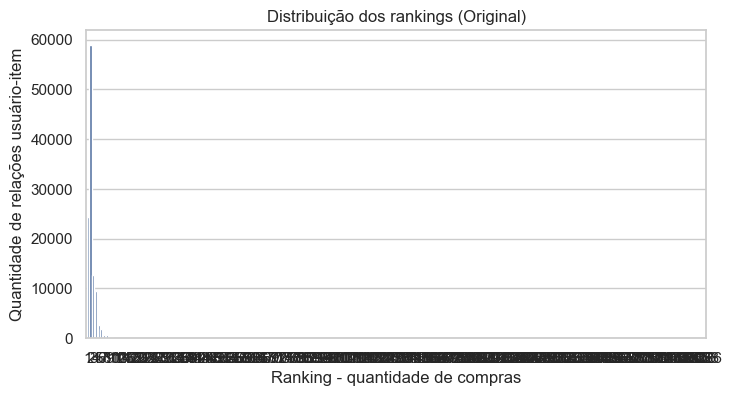

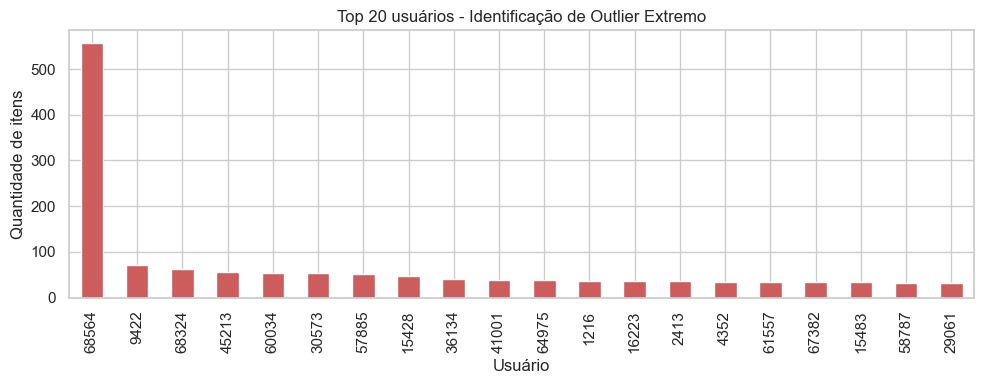

In [134]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_dataset, x="ranking")
plt.title("Distribuição dos rankings (Original)")
plt.xlabel("Ranking - quantidade de compras")
plt.ylabel("Quantidade de relações usuário-item")
plt.show()

plt.figure(figsize=(10, 4))
df_dataset["user_id"].value_counts().head(20).plot(kind="bar", color='indianred')
plt.title("Top 20 usuários - Identificação de Outlier Extremo")
plt.xlabel("Usuário")
plt.ylabel("Quantidade de itens")
plt.tight_layout()
plt.show()

### 3.2) Tratamento de Outliers para Balanceamento

A análise visual anterior revelou a presença de um **outlier extremo** (usuário com mais de 500 interações), o que indica provavelmente um perfil institucional ou erro de coleta, já que distorce completamente a média de consumo. 

Para equilibrar o dataset e evitar que o modelo de recomendação seja enviesado, aplicaremos um filtro de **limpeza por percentil**, removendo o topo 0.1% dos usuários com maior volume de compras.

In [135]:
# Definindo o limite de corte (Percentil 99.9)
limite_corte = df_dataset["user_id"].value_counts().quantile(0.999)

# Identificando usuários acima do limite
contagem_user = df_dataset["user_id"].value_counts()
usuarios_remover = contagem_user[contagem_user > limite_corte].index

# Criando o dataset balanceado
df_dataset_bal = df_dataset[~df_dataset["user_id"].isin(usuarios_remover)].copy()

# Salvando o dataset balanceado para o CSV final
df_dataset_bal.to_csv("../dataset/dataset.csv", index=False)

print(f"Usuários removidos (outliers): {list(usuarios_remover)}")
print(f"Volume original: {len(df_dataset)} | Volume pós-balanceamento: {len(df_dataset_bal)}")

Usuários removidos (outliers): [68564, 9422, 68324, 45213, 60034, 30573, 57885, 15428, 36134, 41001, 64975, 1216, 16223, 2413, 4352, 61557, 67382, 15483, 58787, 29061, 7136, 56360, 9940, 44114, 6825, 26088, 45916, 19441, 61948, 66939, 7434, 37671, 20410, 9230, 58129, 39419, 56639, 50280, 57849, 23707, 3797, 26242, 25324, 56349, 27460, 6374, 63261, 14888, 19756, 24504, 55310, 55251, 58606, 21451, 967, 64990, 30071, 54174, 28618, 15707, 68093, 39588, 11936, 29489, 43420]
Volume original: 112347 | Volume pós-balanceamento: 109916


C:\Users\Inteli\AppData\Local\Temp\ipykernel_10140\2446477972.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


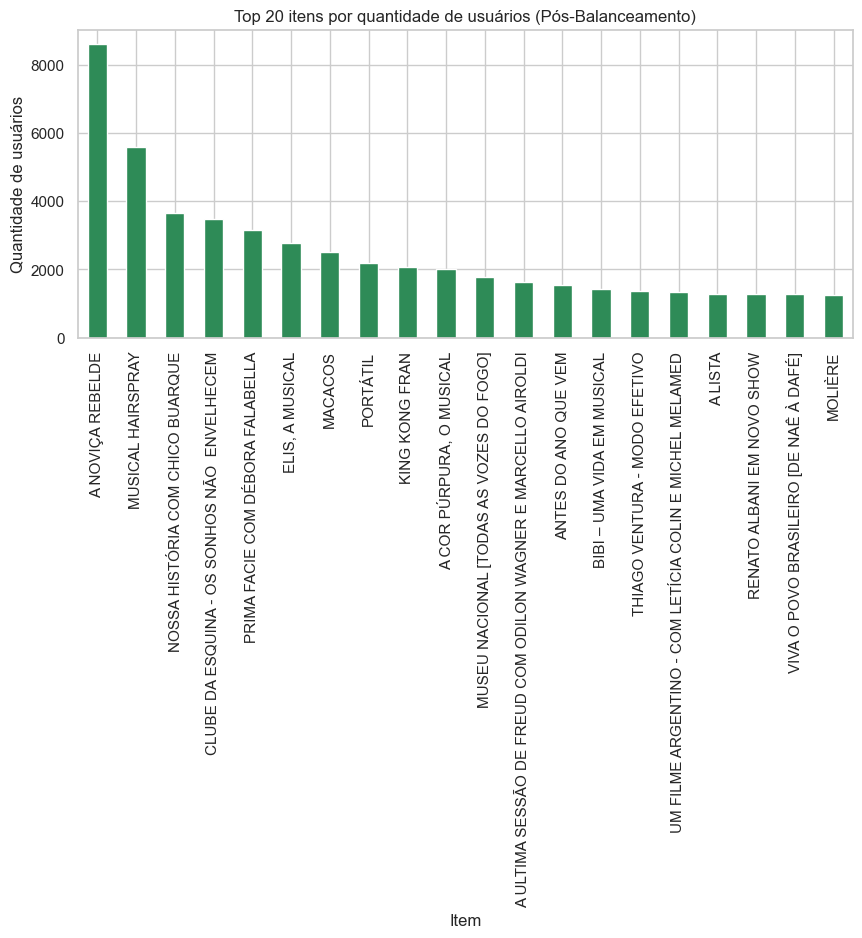

In [136]:
plt.figure(figsize=(10, 4))
df_dataset_bal["item_id"].value_counts().head(20).plot(kind="bar", color='seagreen')
plt.title("Top 20 itens por quantidade de usuários (Pós-Balanceamento)")
plt.xlabel("Item")
plt.ylabel("Quantidade de usuários")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 3.3) Interpretação do balanceamento e Qualidade dos Dados

A distribuição dos rankings indica como as interações usuário-item estão concentradas. Como o ranking foi calculado pela quantidade de compras, valores maiores representam maior intensidade de interação.

Com a remoção dos outliers superiores (normalização), garantimos que usuários institucionais não dominem o cálculo de similaridade do modelo. O dataset resultante apresenta uma esparsidade característica de sistemas de recomendação reais, estando pronto para a aplicação de algoritmos de filtragem colaborativa.

### 3.4) Análise Detalhada de Densidade e Distribuição

Para validar se o balanceamento foi efetivo, precisamos analisar não apenas os "Top Itens", mas como a base se comporta como um todo. Utilizaremos:
1. **Distribuição de Densidade de Interações:** Para ver onde a maioria dos usuários se concentra.
2. **Curva de Lorenz (Popularidade Acumulada):** Para entender o nível de concentração do catálogo.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_10140\1968444933.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_dataset_bal, x="tipo_evento", y="ranking", ax=axes[1], palette="Set3")


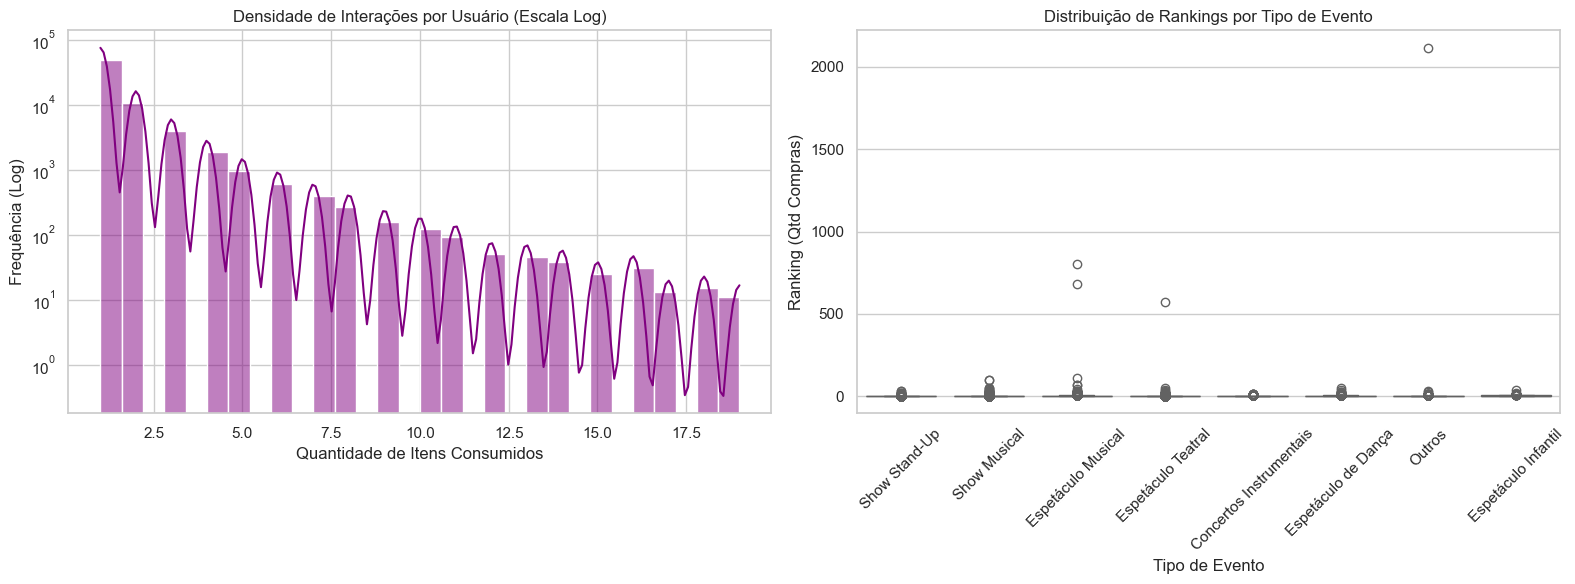

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Histograma de Interações por Usuário (Escala Logarítmica para ver a cauda)
user_counts = df_dataset_bal.groupby("user_id").size()
sns.histplot(user_counts, bins=30, kde=True, ax=axes[0], color="purple")
axes[0].set_yscale('log')
axes[0].set_title("Densidade de Interações por Usuário (Escala Log)")
axes[0].set_xlabel("Quantidade de Itens Consumidos")
axes[0].set_ylabel("Frequência (Log)")

# Gráfico 2: Boxplot de Rankings por Tipo de Evento
# Isso mostra se o balanceamento de 'notas/pesos' está consistente entre categorias
sns.boxplot(data=df_dataset_bal, x="tipo_evento", y="ranking", ax=axes[1], palette="Set3")
axes[1].set_title("Distribuição de Rankings por Tipo de Evento")
axes[1].set_xlabel("Tipo de Evento")
axes[1].set_ylabel("Ranking (Qtd Compras)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

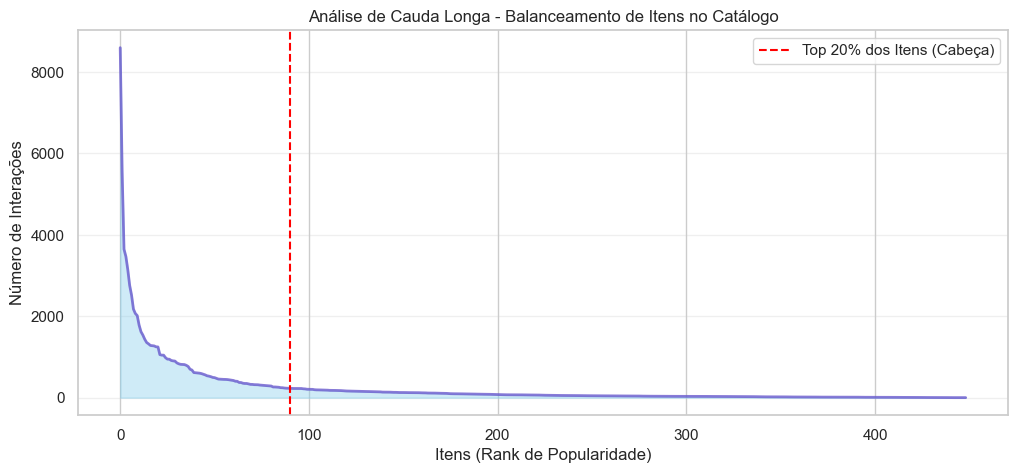

In [138]:
# Preparando dados para a Cauda Longa
item_pop = df_dataset_bal.groupby("item_id").size().sort_values(ascending=False).reset_index()
item_pop.columns = ['item_id', 'count']

plt.figure(figsize=(12, 5))
plt.fill_between(range(len(item_pop)), item_pop['count'], color="skyblue", alpha=0.4)
plt.plot(range(len(item_pop)), item_pop['count'], color="Slateblue", alpha=0.8, linewidth=2)

# Linha de corte simbólica para itens 'Cabeça' vs 'Cauda'
plt.axvline(x=len(item_pop)*0.2, color='red', linestyle='--', label='Top 20% dos Itens (Cabeça)')

plt.title("Análise de Cauda Longa - Balanceamento de Itens no Catálogo")
plt.xlabel("Itens (Rank de Popularidade)")
plt.ylabel("Número de Interações")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

### 3.5) Conclusões sobre a Qualidade da Base Balanceada

Após as intervenções de limpeza e normalização, observamos que:
- **Normalização de Usuários:** O gráfico de densidade (log) mostra que a imensa maioria dos usuários possui um comportamento orgânico de consumo, sem os picos extremos detectados anteriormente.
- **Distribuição de Itens:** A curva de cauda longa confirma que possuímos um conjunto rico de itens de nicho (cauda), o que é ideal para sistemas de recomendação que visam aumentar o *discovery* de novos espetáculos.
- **Consistência por Categoria:** O boxplot indica que o feedback implícito (ranking) mantém uma distribuição similar entre diferentes tipos de eventos, permitindo que o modelo aprenda de forma justa entre categorias.

## 4) Análise complementar da base original

As análises abaixo utilizam a base original para complementar o entendimento dos dados, considerando variáveis que podem apoiar uma futura abordagem híbrida de recomendação.

### 4.1 Distribuição de preço

In [139]:
# Resumo estatístico do preço (unidade em R$)
resumo_preco = (
    df_eda["VALOR_NUM"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .to_frame("Preço (R$)")
    .round(2)
)
resumo_preco

,Preço (R$)
count,343757.00
mean,53.62
std,47.36
min,0.00
25%,20.00
50%,45.00
75%,75.00
90%,120.00
95%,140.00
max,360.00


### 4.2 Composição por tipo, teatro e canal de venda

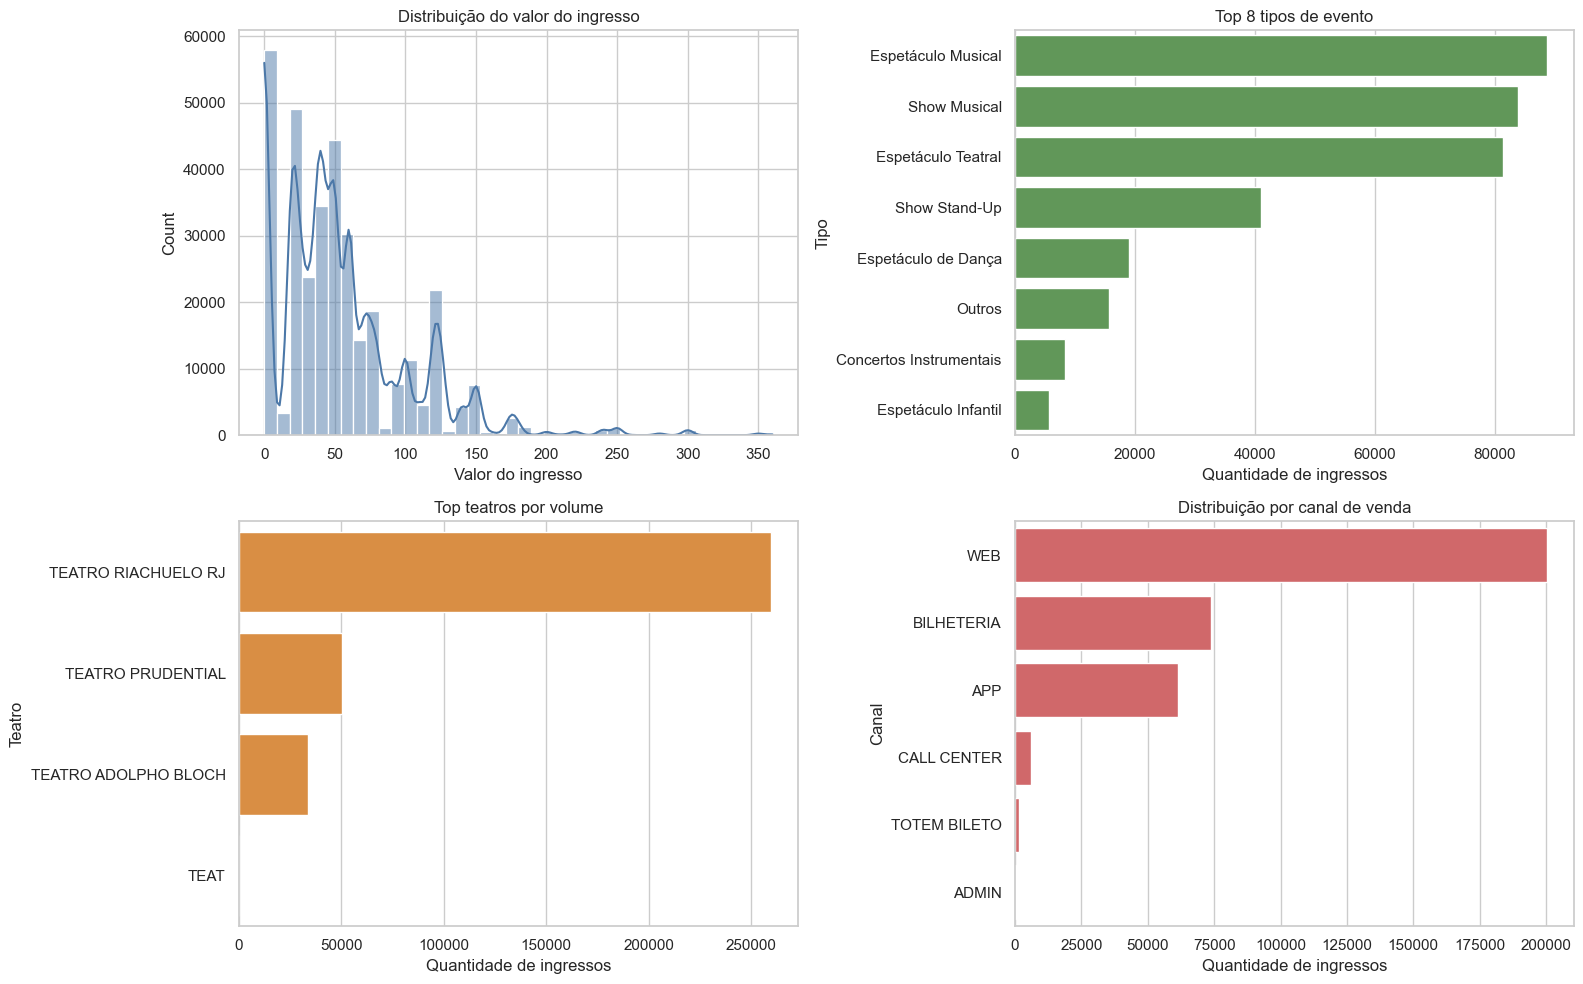

In [140]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Distribuição de valores
sns.histplot(df_eda["VALOR_NUM"].dropna(), bins=40, kde=True, ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Distribuição do valor do ingresso")
axes[0, 0].set_xlabel("Valor do ingresso")

# Top tipos
top_tipos = df_eda["TIPO"].value_counts().head(8)
sns.barplot(x=top_tipos.values, y=top_tipos.index, ax=axes[0, 1], color="#59A14F")
axes[0, 1].set_title("Top 8 tipos de evento")
axes[0, 1].set_xlabel("Quantidade de ingressos")
axes[0, 1].set_ylabel("Tipo")

# Top teatros
top_teatros = df_eda["TEATRO"].value_counts().head(8)
sns.barplot(x=top_teatros.values, y=top_teatros.index, ax=axes[1, 0], color="#F28E2B")
axes[1, 0].set_title("Top teatros por volume")
axes[1, 0].set_xlabel("Quantidade de ingressos")
axes[1, 0].set_ylabel("Teatro")

# Canal de venda
canal_counts = df_eda["CANAL DA VENDA"].value_counts()
sns.barplot(x=canal_counts.values, y=canal_counts.index, ax=axes[1, 1], color="#E15759")
axes[1, 1].set_title("Distribuição por canal de venda")
axes[1, 1].set_xlabel("Quantidade de ingressos")
axes[1, 1].set_ylabel("Canal")

plt.tight_layout()
plt.show()

## 5) Análise bivariada complementar

Comportamento de compra e diferença de preço entre categorias.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_10140\2926988402.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


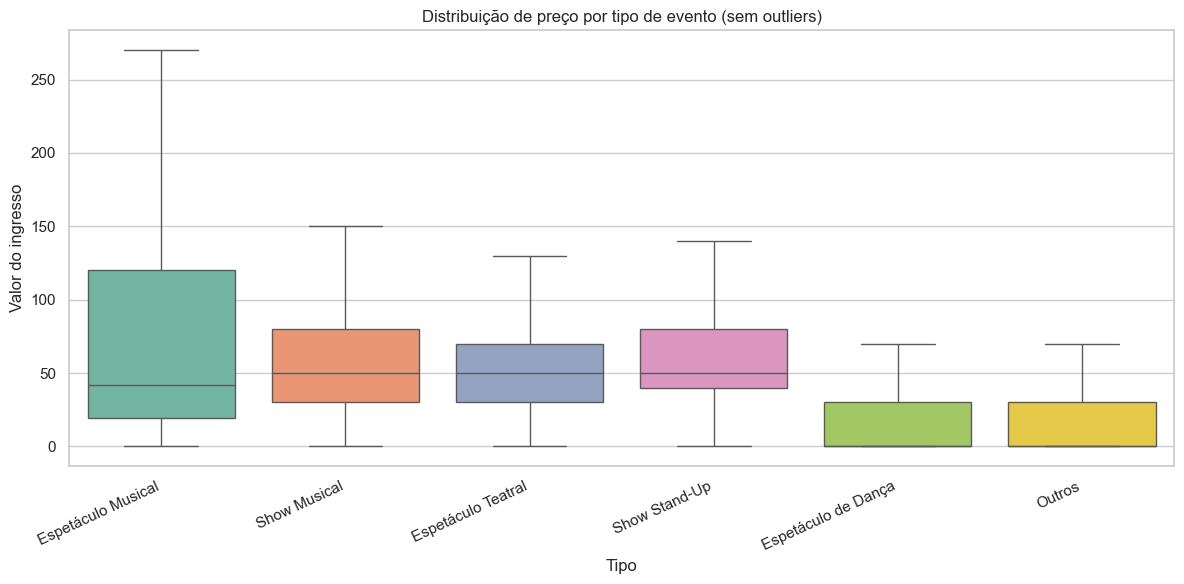

,count,median,mean
TIPO,,,
Espetáculo Teatral,81324,50.0,49.523019
Show Musical,83919,50.0,57.975769
Show Stand-Up,40923,50.0,57.408700
Espetáculo Musical,88738,42.0,69.769237
Espetáculo de Dança,19066,0.0,15.823101
Outros,15677,0.0,15.216596


In [141]:
# Preço por tipo (foco nos tipos com maior volume)
tipos_top = df_eda["TIPO"].value_counts().head(6).index
base_tipos = df_eda[df_eda["TIPO"].isin(tipos_top)].copy()

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=base_tipos,
    x="TIPO",
    y="VALOR_NUM",
    order=tipos_top,
    showfliers=False,
    palette="Set2",
)
plt.xticks(rotation=25, ha="right")
plt.title("Distribuição de preço por tipo de evento (sem outliers)")
plt.xlabel("Tipo")
plt.ylabel("Valor do ingresso")
plt.tight_layout()
plt.show()

base_tipos.groupby("TIPO")["VALOR_NUM"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)

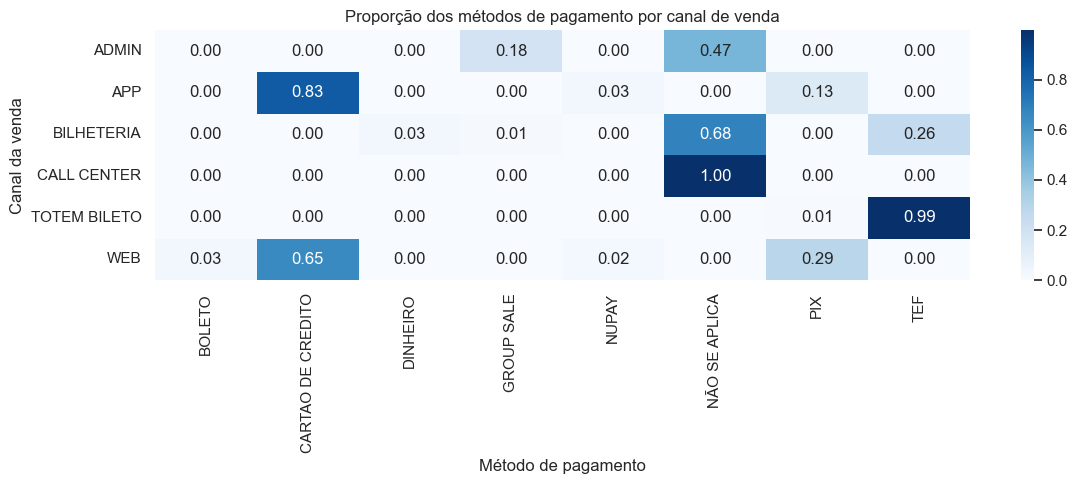

In [142]:
# Relação entre canal de venda e método de pagamento (proporção por canal)
ct = pd.crosstab(df_eda["CANAL DA VENDA"], df_eda["MÉTODO DE PAGAMENTO"], normalize="index")

# Seleciona os métodos mais frequentes para visualização legível
metodos_top = df_eda["MÉTODO DE PAGAMENTO"].value_counts().head(8).index
ct_plot = ct[ct.columns.intersection(metodos_top)]

plt.figure(figsize=(12, 5))
sns.heatmap(ct_plot, annot=True, fmt=".2f", cmap="Blues")
plt.title("Proporção dos métodos de pagamento por canal de venda")
plt.xlabel("Método de pagamento")
plt.ylabel("Canal da venda")
plt.tight_layout()
plt.show()

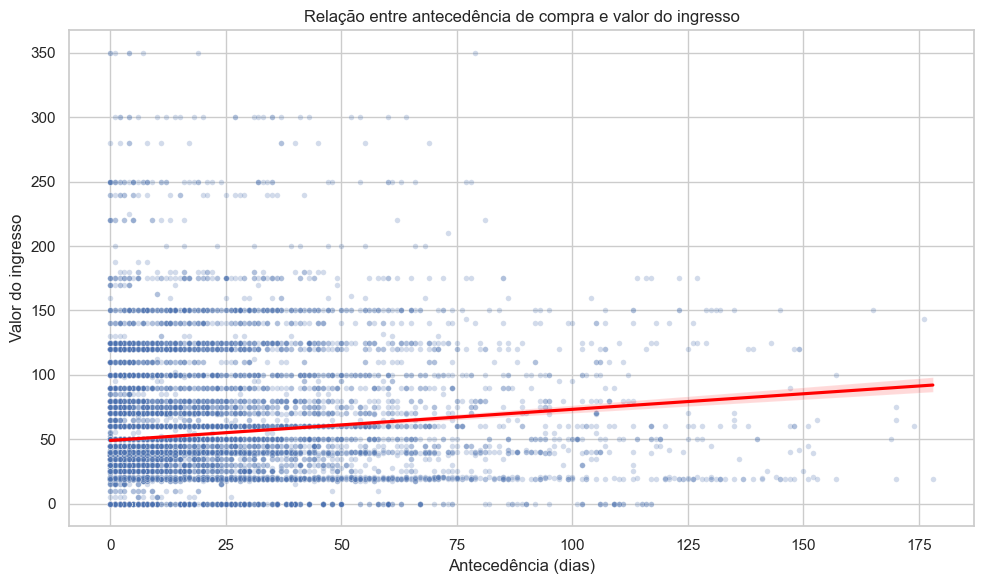

,ANTECEDENCIA_DIAS,VALOR_NUM
ANTECEDENCIA_DIAS,1.000000,0.128443
VALOR_NUM,0.128443,1.000000


In [143]:
# Antecedência de compra vs valor do ingresso (amostra para performance visual)
base_relacao = df_eda[["ANTECEDENCIA_DIAS", "VALOR_NUM"]].dropna().copy()
base_relacao = base_relacao[(base_relacao["ANTECEDENCIA_DIAS"] >= 0) & (base_relacao["ANTECEDENCIA_DIAS"] <= 180)]

amostra = base_relacao.sample(min(12000, len(base_relacao)), random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=amostra, x="ANTECEDENCIA_DIAS", y="VALOR_NUM", alpha=0.25, s=16)
sns.regplot(data=amostra, x="ANTECEDENCIA_DIAS", y="VALOR_NUM", scatter=False, color="red")
plt.title("Relação entre antecedência de compra e valor do ingresso")
plt.xlabel("Antecedência (dias)")
plt.ylabel("Valor do ingresso")
plt.tight_layout()
plt.show()

amostra[["ANTECEDENCIA_DIAS", "VALOR_NUM"]].corr()

## 6) Sequenciamento e priorização da entrega

A entrega foi organizada em etapas sequenciais. Primeiro, foi realizada a importação e limpeza da base original. Em seguida, foi criado o dataset final para recomendação, estruturado com `user_id`, `item_id`, `ranking`, `valor_medio_ingresso` e `tipo_evento`.

Após a geração do CSV, o dataset foi carregado novamente no notebook para validação, descrição estatística e análise de balanceamento. Por fim, foram realizadas análises complementares da base original para apoiar possíveis evoluções futuras do sistema de recomendação.

A prioridade principal foi garantir a estrutura mínima exigida para filtragem colaborativa, com usuário, item e ranking. As variáveis adicionais foram mantidas como apoio para análises futuras e possíveis abordagens híbridas.

## 7) Conclusão

O dataset final foi estruturado para alimentar um sistema de recomendação, contendo `user_id`, `item_id`, `ranking`, `valor_medio_ingresso` e `tipo_evento`.

Como a base original não possui avaliações explícitas dos usuários, o `ranking` foi construído como feedback implícito, representando a quantidade de compras de cada usuário para cada espetáculo.

A análise exploratória permitiu verificar a estrutura, a qualidade e o balanceamento do dataset. As variáveis complementares, como valor médio do ingresso e tipo do evento, podem apoiar evoluções futuras para uma abordagem híbrida de recomendação.